# HAMS Data Science Challenge: Bayesian Marketing Mix Model

**Goal.** Explain weekly revenue of company X from its spend in seven paid channels, accounting for the
delayed (carry-over) effect of advertising, and derive a return on investment (ROI) per channel with honest uncertainty.

**Model in one line.**

$$\text{revenue}_t = \underbrace{\mu_0 + \tau\, t}_{\text{baseline + trend}} + \underbrace{\textstyle\sum_k a_k \sin\tfrac{2\pi k t}{52.18} + b_k \cos\tfrac{2\pi k t}{52.18}}_{\text{yearly seasonality}} + \underbrace{\gamma\,\text{cyber}_t}_{\text{Cyber Week}} + \sum_{c=1}^{7} \beta_c\, \text{adstock}(x_c)_t + \varepsilon_t$$

Everything is written directly in PyMC (no PyMC-Marketing) so every piece is visible.

**Notebook outline**
1. Setup
2. Data loading and checks
3. Exploratory analysis
4. Feature preparation (scaling, adstock lags, seasonality, Cyber Week indicator)
5. Model definition
6. Prior predictive check
7. Fitting the main model and its variants
8. Model comparison (LOO)
9. Sampling diagnostics
10. Posterior predictive check, fit metrics and time-based holdout
11. Prior vs. posterior
12. Channel contributions and ROI
13. Sensitivity of the ROI ranking
14. Summary

## 1. Setup

**Note on `PYTENSOR_FLAGS`.** PyTensor (PyMC's computational backend) normally compiles C code. On recent macOS
toolchains its linker flag `-ld64` is no longer accepted, so compilation fails. Setting `cxx=` makes PyTensor use its
pure-Python/NumPy backend instead. The model is small, so each fit still takes only ~10 seconds, and the results are
identical. This line is harmless on other systems.

In [1]:
import os

os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")

import warnings

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
RNG = np.random.default_rng(SEED)
FIG_DIR = "figures"
RESULTS_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Report 94% highest-density intervals everywhere
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = 0.94

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

print(f"PyMC {pm.__version__} | ArviZ {az.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")


def savefig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

PyMC 6.3.2 | ArviZ 1.3.0 | NumPy 2.5.4 | pandas 3.0.6


## 2. Data loading and checks

Dates are day-first (`30-08-20`), so the format is passed explicitly rather than guessed.

In [2]:
df = pd.read_csv("MMM_test_data.csv")
df["start_of_week"] = pd.to_datetime(df["start_of_week"], format="%d-%m-%y")

SPEND_COLS = [c for c in df.columns if c.startswith("spend_channel")]
CHANNELS = [c.replace("spend_", "") for c in SPEND_COLS]
dates = df["start_of_week"].values
T, C = len(df), len(SPEND_COLS)

print(f"{T} weeks, {df.start_of_week.min():%Y-%m-%d} to {df.start_of_week.max():%Y-%m-%d}")
print("Gaps between rows:", df.start_of_week.diff().dropna().value_counts().to_dict())
print("Missing values:", int(df.isna().sum().sum()), "| Negative values:", int((df[["revenue"] + SPEND_COLS] < 0).sum().sum()))
print(f"Total spend / total revenue: {df[SPEND_COLS].sum().sum() / df.revenue.sum():.1%}")
df.describe().T.round(0)

104 weeks, 2020-08-30 to 2022-08-21
Gaps between rows: {Timedelta('7 days 00:00:00'): 103}
Missing values: 0 | Negative values: 0
Total spend / total revenue: 50.8%


,count,mean,min,25%,50%,75%,max,std
start_of_week,104,2021-08-25 12:00:00,2020-08-30 00:00:00,2021-02-26 06:00:00,2021-08-25 12:00:00,2022-02-21 18:00:00,2022-08-21 00:00:00,NaN
revenue,104.0,136490.190673,63207.09,101675.685,128790.46,157707.28,418186.38,50810.253012
spend_channel_1,104.0,1245.604808,0.0,334.275,856.87,1658.0325,8513.83,1388.384632
spend_channel_2,104.0,343.640962,4.37,120.47,202.02,553.075,1605.85,332.988218
spend_channel_3,104.0,19507.177981,5938.13,13879.0,17929.45,22252.2625,49689.38,8714.759886
spend_channel_4,104.0,6915.136731,3602.2,5113.9375,6194.4,7470.5575,22629.69,3123.172035
spend_channel_5,104.0,8575.611442,747.46,2902.0325,6879.27,14367.5825,33009.65,6956.787524
spend_channel_6,104.0,5063.699038,0.0,0.0,2423.095,8701.96,33692.83,6689.47266
spend_channel_7,104.0,27701.367404,9391.21,19797.71,24248.64,33852.6525,77488.42,12176.293684


The data is clean: 104 consecutive weeks, no gaps, no missing or negative values.

**Total spend is ~51% of total revenue.** This is the single most useful number for setting priors: if every channel
returned exactly 1 € per € spent, advertising would explain about half of all revenue.

## 3. Exploratory analysis

### 3.1 Revenue over time: where are the spikes, and do they repeat?

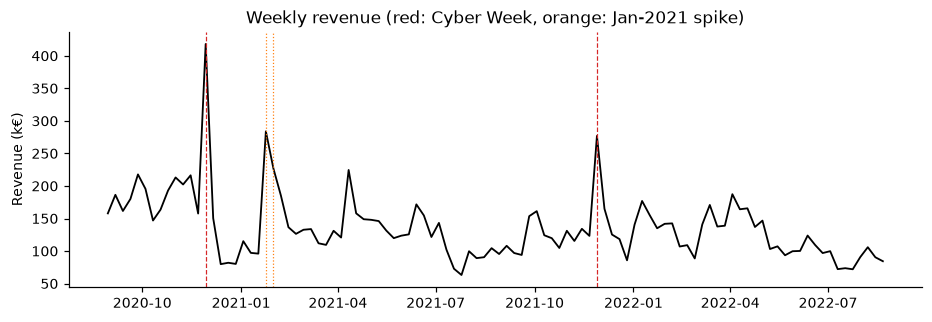

start_of_week   revenue
   2020-11-29 418186.38
   2021-01-24 284010.24
   2021-11-28 276991.38
   2021-01-31 226994.32
   2021-04-11 224619.82
   2020-09-27 217793.98


In [3]:
CYBER_WEEKS = pd.to_datetime(["2020-11-29", "2021-11-28"])  # weeks containing Cyber Monday (right after Black Friday)
JAN_SPIKE = pd.to_datetime(["2021-01-24", "2021-01-31"])

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df.start_of_week, df.revenue / 1e3, color="k", lw=1.2)
for d in CYBER_WEEKS:
    ax.axvline(d, color="tab:red", ls="--", lw=0.8)
for d in JAN_SPIKE:
    ax.axvline(d, color="tab:orange", ls=":", lw=0.8)
ax.set(ylabel="Revenue (k€)", title="Weekly revenue (red: Cyber Week, orange: Jan-2021 spike)")
savefig(fig, "eda_revenue")
plt.show()

print(df.nlargest(6, "revenue")[["start_of_week", "revenue"]].to_string(index=False))

- The two largest repeatable peaks are the **Cyber Week** weeks (the week starting the Sunday after Black Friday,
  containing Cyber Monday): 418k in 2020 and 277k in 2021.
- **Late January 2021** (284k, 227k) does **not** repeat in 2022. That is a one-off event, not seasonality. We won't
  add a dummy for it (that would be fitting noise by hand); a heavy-tailed Student-t likelihood can absorb it instead.
- Revenue dips every **July** in both years: a genuine, repeating summer low.

### 3.2 Spend per channel: the year-2 mix shift

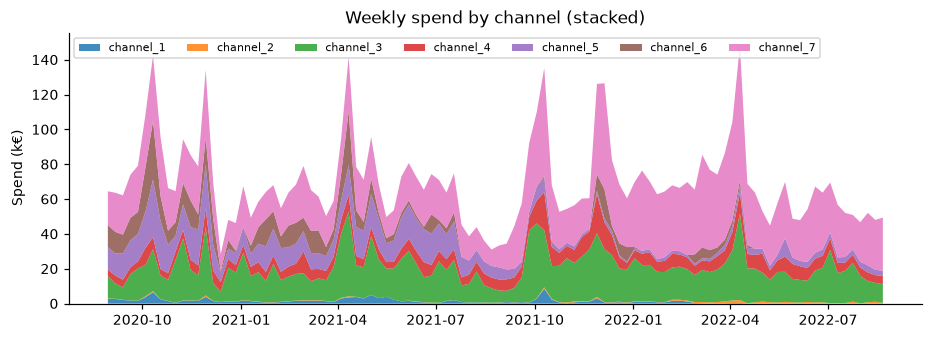

,year 1 mean,year 2 mean,change,zero-spend weeks
spend_channel_1,"1,785",706,-60%,13
spend_channel_2,172,516,+200%,0
spend_channel_3,"18,386","20,628",+12%,0
spend_channel_4,"5,842","7,988",+37%,0
spend_channel_5,"14,127","3,024",-79%,0
spend_channel_6,"8,632","1,495",-83%,39
spend_channel_7,"21,004","34,399",+64%,0
revenue,"149,056","123,924",-17%,0


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.stackplot(df.start_of_week, (df[SPEND_COLS] / 1e3).T.values, labels=CHANNELS, alpha=0.85)
ax.set(ylabel="Spend (k€)", title="Weekly spend by channel (stacked)")
ax.legend(ncol=7, fontsize=7, loc="upper left")
savefig(fig, "eda_spend")
plt.show()

year1, year2 = df.iloc[:52], df.iloc[52:]
mix = pd.DataFrame(
    {
        "year 1 mean": year1[SPEND_COLS + ["revenue"]].mean(),
        "year 2 mean": year2[SPEND_COLS + ["revenue"]].mean(),
    }
)
mix["change"] = mix["year 2 mean"] / mix["year 1 mean"] - 1
mix["zero-spend weeks"] = (df[SPEND_COLS + ["revenue"]] == 0).sum()
mix.style.format({"year 1 mean": "{:,.0f}", "year 2 mean": "{:,.0f}", "change": "{:+.0%}"})

**Year 2 replaced channels 5 and 6 with channel 7, and revenue fell by ~17%** while total spend stayed about the same.
A model will likely conclude that channels 5 and 6 work better than 7. But a downward trend could explain the same
drop, so **trend and these channel effects are partly confounded**. This is the biggest identifiability risk in
the data and we come back to it in sections 9 and 12.

### 3.3 Correlation between channels: which effects can be separated?

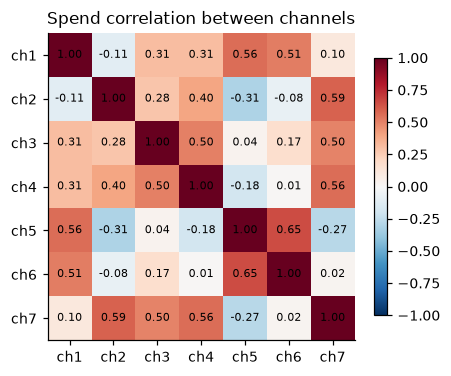

In [5]:
corr = df[SPEND_COLS].corr()
fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(C), [c.replace("channel_", "ch") for c in CHANNELS])
ax.set_yticks(range(C), [c.replace("channel_", "ch") for c in CHANNELS])
for i in range(C):
    for j in range(C):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spend correlation between channels")
savefig(fig, "eda_spend_corr")
plt.show()

The strongest pairs are channel 5–6 (0.65), 2–7, 4–7 and 1–5 (~0.56–0.59). When two channels' spend moves together,
the data can tell us their combined effect better than each one separately, and their individual posteriors will be
negatively correlated.

### 3.4 Is there carry-over? Revenue vs. lagged spend

A rough first look: correlation between revenue in week $t$ and spend in week $t-l$. This ignores seasonality and the
other channels, so it only hints at whether effects persist beyond the current week.

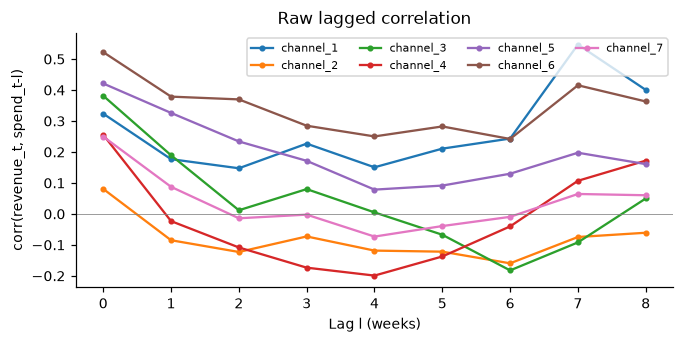

In [6]:
LAGS = range(0, 9)
lag_corr = pd.DataFrame(
    {ch: [df.revenue.corr(df[col].shift(l)) for l in LAGS] for ch, col in zip(CHANNELS, SPEND_COLS)}, index=LAGS
)
fig, ax = plt.subplots(figsize=(7, 3))
lag_corr.plot(ax=ax, marker="o", ms=3)
ax.axhline(0, color="grey", lw=0.5)
ax.set(xlabel="Lag l (weeks)", ylabel="corr(revenue_t, spend_t-l)", title="Raw lagged correlation")
ax.legend(ncol=4, fontsize=7)
savefig(fig, "eda_lag_corr")
plt.show()

Correlations are largest at lag 0 and fade over a few weeks for most channels. That is consistent with a carry-over
effect that decays geometrically, with most of it gone within ~4–8 weeks. It supports a maximum lag of 8 weeks.

### 3.5 How much does seasonality repeat year over year?

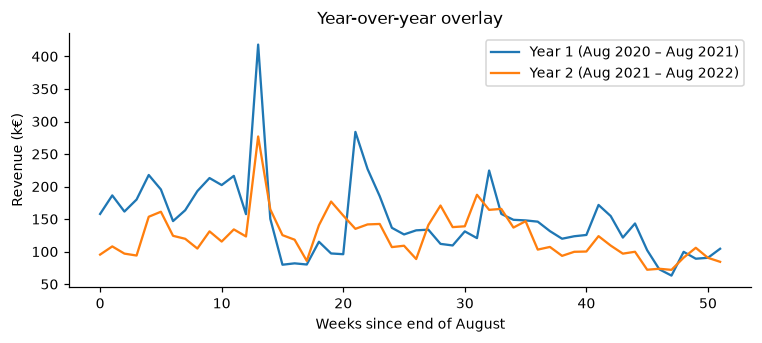

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(52), year1.revenue.values / 1e3, label="Year 1 (Aug 2020 – Aug 2021)")
ax.plot(np.arange(52), year2.revenue.values / 1e3, label="Year 2 (Aug 2021 – Aug 2022)")
ax.set(xlabel="Weeks since end of August", ylabel="Revenue (k€)", title="Year-over-year overlay")
ax.legend()
savefig(fig, "eda_yoy")
plt.show()

The broad shape repeats (autumn high, Cyber Week peak, summer low), but year 2 sits lower overall. With only two
years, each season appears twice, so seasonality should be kept **smooth** (few Fourier terms, see section 4).

## 4. Feature preparation

**Scaling.** Revenue **and all spend columns are divided by the same number**, the mean weekly revenue. Because the
model is linear in spend (no saturation) and adstock weights sum to 1 (see below), the channel coefficient $\beta_c$ is
then **directly the ROI**: revenue generated per € spent. A prior on $\beta_c$ is a prior on ROI, which we can argue
about in business terms. (Scaling each channel by its own maximum would make the same $\beta$ prior imply a ~48× higher
ROI for channel 2 than for channel 7.)

**Time.** $t$ runs from 0 to 1 over the two years, so the trend coefficient is "change over the full period".

**Seasonality.** $K=2$ yearly Fourier pairs (period 52.18 weeks): enough for one broad summer dip and an autumn bump;
$K=3$ is tested in section 8.

**Cyber Week indicator.** 1 in the two Cyber Week weeks, 0 otherwise. Spend in almost every channel also jumps in those
weeks, so without the indicator the model could credit the event to the ads. Section 8 compares fits with and without it.

In [8]:
SCALE = df.revenue.mean()
y = df.revenue.values / SCALE
X = df[SPEND_COLS].values / SCALE
t = np.arange(T) / (T - 1)
CYBER = df.start_of_week.isin(CYBER_WEEKS).astype(float).values


def lag_tensor(X, L):
    """Array of shape (weeks, channels, L+1) with X_lag[t, c, l] = spend of channel c in week t-l (0 before the data starts)."""
    T, C = X.shape
    out = np.zeros((T, C, L + 1))
    for l in range(L + 1):
        out[l:, :, l] = X[: T - l]
    return out


def fourier_terms(n_weeks, K, period=52.18):
    w = np.arange(n_weeks)
    cols, names = [], []
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * w / period), np.cos(2 * np.pi * k * w / period)]
        names += [f"sin_{k}", f"cos_{k}"]
    return np.column_stack(cols), names


print(f"Scale (mean weekly revenue): {SCALE:,.0f} €")

Scale (mean weekly revenue): 136,490 €


## 5. Model definition

### Carry-over (adstock)
Normalised **geometric adstock** with one decay rate $\alpha_c \in (0,1)$ per channel and maximum lag $L=8$:

$$\text{adstock}(x_c)_t = \frac{\sum_{l=0}^{L} \alpha_c^{\,l}\, x_{c,t-l}}{\sum_{l=0}^{L} \alpha_c^{\,l}}$$

- $\alpha_c$ is the fraction of this week's effect still present next week ($\alpha=0.5$: half remains after one week).
- **Normalising** the weights to sum to 1 means one € of spend is *spread out* over the following weeks, not multiplied.
  So $\beta_c$ stays "total revenue per €" whatever $\alpha_c$ is. Without it, $\alpha$ and $\beta$ trade off against each
  other (slower decay inflates adstocked spend and shrinks $\beta$), which hurts both sampling and interpretation.
- **Implementation:** the lagged-spend array is built once in NumPy; inside the model the weights $\alpha_c^l$ are a
  PyTensor expression and the adstock is a weighted sum over the lag axis. Fully vectorised, no loops.
- **Start of the series:** the first $L=8$ weeks have no earlier spend to carry over, so their adstock is biased
  low. We compute adstock on the full series but **fit only weeks 9–104** (96 observations).

### Priors (on the scaled data, where mean revenue = 1)

| Parameter | Prior | Reason |
|---|---|---|
| $\beta_c$ (ROI) | HalfNormal(1) | Ads can't reduce revenue, so ROI ≥ 0. Median ≈ 0.67, 97.5% quantile ≈ 2.2: wide, but rules out absurd ROIs like 20. |
| $\alpha_c$ (decay) | Beta(2, 2) | Must be in (0, 1). Centred on 0.5 because we don't know which channel is TV and which is search. Rules out the extremes "no carry-over" and "never decays". |
| $\mu_0$ (baseline) | Normal(0.6, 0.25) | Revenue without ads, trend or season. If ads explain a third to half of revenue, the baseline is ~0.5–0.7. |
| $\tau$ (trend) | Normal(0, 0.3) | Allows up to ~±60% change over two years, no assumed direction (raw drop: −17%). |
| $a_k, b_k$ (Fourier) | Normal(0, 0.2) | Seasonal swings of ±20–40% of mean are plausible (July is ~35% below average); shrinks to 0 if unsupported. |
| $\gamma$ (Cyber Week) | HalfNormal(1) | The event can only raise revenue; allows up to about +2× mean revenue. |
| $\sigma$ (noise) | HalfNormal(0.3) | Revenue varies by ±37% around its mean (CV); the model explains part of that, so residual noise should be smaller. |
| $\nu$ (Student-t dof) | Gamma(2, 0.1) | Standard weakly informative choice; lets the data choose between heavy tails ($\nu<5$) and near-Normal ($\nu>30$). |

In [9]:
def build_mmm(fit_idx, L=8, K=2, likelihood="studentt", cyber=True, beta_sigma=1.0):
    """Bayesian MMM on scaled data. fit_idx: indices of the weeks used in the likelihood."""
    X_lag = lag_tensor(X, L)[fit_idx]  # (N, C, L+1)
    F, f_names = fourier_terms(T, K)
    coords = {"channel": CHANNELS, "fourier": f_names, "week": dates[fit_idx]}

    with pm.Model(coords=coords) as model:
        # --- priors ---
        alpha = pm.Beta("alpha", 2, 2, dims="channel")  # adstock decay
        beta = pm.HalfNormal("beta", beta_sigma, dims="channel")  # ROI (revenue per € spent)
        baseline = pm.Normal("baseline", 0.6, 0.25)
        trend = pm.Normal("trend", 0, 0.3)
        gamma = pm.Normal("gamma", 0, 0.2, dims="fourier")
        sigma = pm.HalfNormal("sigma", 0.3)

        # --- normalised geometric adstock ---
        weights = alpha[:, None] ** np.arange(L + 1)[None, :]  # (C, L+1)
        weights = weights / weights.sum(axis=1, keepdims=True)
        adstock = (X_lag * weights[None, :, :]).sum(axis=-1)  # (N, C)

        # --- components ---
        channel_contrib = pm.Deterministic("channel_contrib", adstock * beta, dims=("week", "channel"))
        seasonality = pm.Deterministic("seasonality", pt.dot(F[fit_idx], gamma), dims="week")
        mu = baseline + trend * t[fit_idx] + seasonality + channel_contrib.sum(axis=1)
        if cyber:
            cyber_effect = pm.HalfNormal("cyber_effect", 1.0)
            mu = mu + cyber_effect * CYBER[fit_idx]
        mu = pm.Deterministic("mu", mu, dims="week")

        # --- likelihood ---
        if likelihood == "studentt":
            nu = pm.Gamma("nu", 2, 0.1)
            pm.StudentT("revenue", nu=nu, mu=mu, sigma=sigma, observed=y[fit_idx], dims="week")
        else:
            pm.Normal("revenue", mu=mu, sigma=sigma, observed=y[fit_idx], dims="week")
    return model


L_MAIN = 8
FIT_IDX = np.arange(L_MAIN, T)  # weeks 9..104
main_model = build_mmm(FIT_IDX)
print("Free parameters:", [rv.name for rv in main_model.free_RVs])

Free parameters: ['alpha', 'beta', 'baseline', 'trend', 'gamma', 'sigma', 'cyber_effect', 'nu']


## 6. Prior predictive check

Before seeing the data: do the priors generate plausible revenue? We draw 1,000 parameter sets from the priors, push them
through the model and compare the implied revenue with the actual series.

**Pass criteria:** the bands cover the data and mostly stay within ~0–4× mean revenue; the implied share of revenue
driven by ads is spread widely, not pinned to 0% or 100%.

Sampling: [alpha, baseline, beta, cyber_effect, gamma, nu, revenue, sigma, trend]


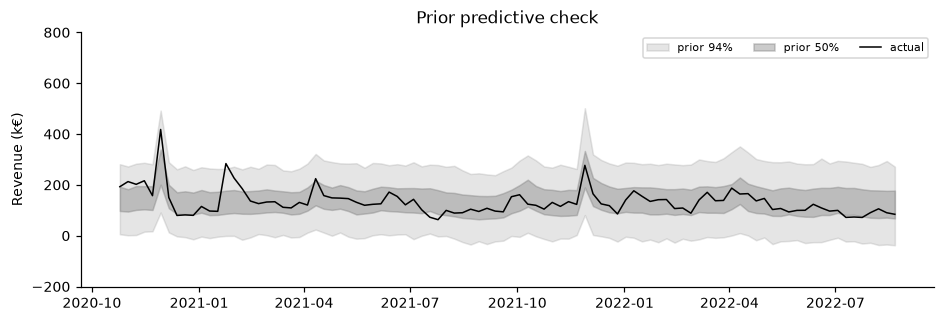

Prior predictive: share of draws with negative weekly revenue: 3.8%
Prior predictive: weekly revenue 94% range: -9,856 to 296,233 €
Prior implied share of revenue from ads: median 39%, 94% range 16%–85%


In [10]:
with main_model:
    prior = pm.sample_prior_predictive(draws=1000, random_seed=SEED)


def stacked(data, var, group="posterior"):
    """Draws of `var` as a NumPy array with all chains/draws stacked on axis 0."""
    da = data[group][var]
    return da.stack(sample=("chain", "draw")).transpose("sample", ...).values


def plot_bands(ax, x, draws, actual, color, label):
    q03, q25, q50, q75, q97 = np.quantile(draws, [0.03, 0.25, 0.5, 0.75, 0.97], axis=0)
    ax.fill_between(x, q03, q97, color=color, alpha=0.2, label=f"{label} 94%")
    ax.fill_between(x, q25, q75, color=color, alpha=0.4, label=f"{label} 50%")
    ax.plot(x, actual, color="k", lw=1, label="actual")


prior_rev = stacked(prior, "revenue", "prior_predictive") * SCALE
fig, ax = plt.subplots(figsize=(10, 3))
plot_bands(ax, dates[FIT_IDX], prior_rev / 1e3, df.revenue.values[FIT_IDX] / 1e3, "tab:grey", "prior")
ax.set(ylabel="Revenue (k€)", title="Prior predictive check", ylim=(-200, 800))
ax.legend(ncol=3, fontsize=7)
savefig(fig, "prior_predictive")
plt.show()

prior_ads_share = stacked(prior, "channel_contrib", "prior").sum(axis=(1, 2)) / stacked(prior, "mu", "prior").sum(axis=1)
print(f"Prior predictive: share of draws with negative weekly revenue: {(prior_rev < 0).mean():.1%}")
print(f"Prior predictive: weekly revenue 94% range: {np.quantile(prior_rev, 0.03):,.0f} to {np.quantile(prior_rev, 0.97):,.0f} €")
print("Prior implied share of revenue from ads: median {:.0%}, 94% range {:.0%}–{:.0%}".format(*np.quantile(prior_ads_share, [0.5, 0.03, 0.97])))

The prior predictive bands are wide and cover the actual revenue everywhere except the one-off January 2021 spike, and
they stay in a plausible range (94% of weekly draws between about −10k and 300k €). The implied share of revenue from ads is spread broadly: the priors are weakly informative
and leave the decision to the data. A small fraction of draws goes negative; that comes from the Normal priors and
heavy Student-t tails, is far from the observed data and is overruled once the model is fitted.

## 7. Fitting the main model and its variants

Sampling uses NUTS (the default Hamiltonian Monte Carlo sampler): 4 chains × 1,000 draws after 1,000 tuning steps, with
`target_accept=0.95` (smaller step size, avoids the few divergences seen at 0.9). The log-likelihood is stored for LOO.

**Main model:** Student-t likelihood, Cyber Week indicator, $K=2$, $L=8$. The Student-t likelihood was chosen up front
because of the January 2021 one-off spike; section 8 checks this choice. Variants, each changing one thing:
- `normal`: Normal instead of Student-t likelihood
- `no_cyber`: without the Cyber Week indicator
- `fourier_K3`: three instead of two Fourier pairs

In [11]:
SAMPLE_KW = dict(draws=1000, tune=1000, chains=4, target_accept=0.95, random_seed=SEED, progressbar=False,
                 idata_kwargs={"log_likelihood": True})


def fit(model):
    with model:
        idata = pm.sample(**SAMPLE_KW)
        pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=SEED, progressbar=False)
    return idata


idata = fit(main_model)
idata.update(prior)  # keep prior draws next to the posterior for comparison

variants = {
    "studentt (main)": idata,
    "normal": fit(build_mmm(FIT_IDX, likelihood="normal")),
    "no_cyber": fit(build_mmm(FIT_IDX, cyber=False)),
    "fourier_K3": fit(build_mmm(FIT_IDX, K=3)),
}

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, baseline, trend, gamma, sigma, cyber_effect, nu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Sampling: [revenue]


...

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, baseline, trend, gamma, sigma, cyber_effect, nu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Sampling: [revenue]


## 8. Model comparison (PSIS-LOO)

**PSIS-LOO** (Pareto-smoothed importance sampling leave-one-out) estimates how well each model would predict a week it
hasn't seen, from a single fit. Higher `elpd` is better. A difference is meaningful when it is several times its
standard error `dse`. The Pareto-k diagnostic flags influential weeks (k > 0.7 makes the estimate for that week
unreliable).

Caveat: LOO treats weeks as exchangeable, but adstock and trend make neighbouring weeks dependent, so this is an
approximation, best used for *relative* comparison.

In [12]:
comparison = az.compare(variants, round_to=None)
comparison = comparison[["rank", "elpd", "se", "elpd_diff", "dse", "p", "weight"]].astype(float)
display(comparison.round(2))
comparison.to_csv(f"{RESULTS_DIR}/loo_comparison.csv")

for name, d in variants.items():
    k = az.loo(d).pareto_k.values
    ch5 = stacked(d, "beta")[:, CHANNELS.index("channel_5")]
    print(f"{name:16s} Pareto-k > 0.7: {(k > 0.7).sum()} weeks | divergences: {int(d.sample_stats.diverging.sum())} "
          f"| sigma median {np.median(stacked(d, 'sigma')) * SCALE:,.0f} €")

variant_roi = pd.DataFrame({name: np.median(stacked(d, "beta"), 0) for name, d in variants.items()}, index=CHANNELS).T
print("Median ROI per channel under each variant:")
display(variant_roi.round(2))
variant_roi.to_csv(f"{RESULTS_DIR}/variant_roi.csv")

,rank,elpd,se,elpd_diff,dse,p,weight
fourier_K3,0.0,4.0,11.0,0.00,0.0,18.0,0.31
studentt (main),1.0,3.6,11.0,-0.42,1.9,17.0,0.00
normal,2.0,-1.4,13.0,-5.30,5.6,14.0,0.39
no_cyber,3.0,-1.7,12.0,-5.70,5.3,13.0,0.30


studentt (main)  Pareto-k > 0.7: 0 weeks | divergences: 0 | sigma median 22,541 €
normal           Pareto-k > 0.7: 3 weeks | divergences: 0 | sigma median 30,774 €


no_cyber         Pareto-k > 0.7: 0 weeks | divergences: 0 | sigma median 19,956 €
fourier_K3       Pareto-k > 0.7: 0 weeks | divergences: 0 | sigma median 23,322 €
Median ROI per channel under each variant:


,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6,channel_7
studentt (main),0.49,0.68,0.76,0.36,1.79,1.08,0.97
normal,0.49,0.68,0.73,0.39,2.05,1.27,0.76
no_cyber,0.54,0.66,0.77,0.46,1.47,0.94,1.01
fourier_K3,0.49,0.68,0.83,0.36,1.75,1.49,1.05


**Reading the comparison**
- **All differences are small relative to their uncertainty** (|elpd_diff| ≈ 0.4–6 with dse ≈ 2–6, i.e. ≤ ~1 SE).
  With 96 weeks, LOO cannot strongly separate these variants, and we don't claim it does.
- **Student-t vs. Normal:** Student-t is ~5 elpd ahead (≈ 1 SE). More telling: the Normal model has 3 influential weeks
  (Pareto-k > 0.7) against none for Student-t, so it is pulled around by single spikes. The posterior of $\nu$ (≈ 6,
  below) also points to moderately heavy tails. We keep Student-t.
- **Cyber Week indicator:** dropping it costs ~6 elpd (≈ 1 SE). Without it, smooth seasonality can't produce a one-week
  spike, so the ads and the heavy Student-t tails must absorb it. We keep it on domain grounds: it is a known retail event.
- **$K=3$ vs. $K=2$:** a negligible difference (~0.4 elpd, well within 1 SE), so we keep the simpler $K=2$.
- Across all four variants channel 5 has the highest median ROI, so the main conclusion does not depend on these
  choices.

The main model (Student-t, Cyber Week indicator, $K=2$) is used for everything that follows.

## 9. Sampling diagnostics

Targets: $\hat R < 1.01$ (chains agree), bulk and tail ESS > 400 (enough independent draws), zero divergences
(the sampler explored the posterior without numerical trouble).

In [13]:
PARAMS = ["baseline", "trend", "gamma", "cyber_effect", "sigma", "nu", "alpha", "beta"]
summary = az.summary(idata, var_names=PARAMS)
display(summary)
summary.to_csv(f"{RESULTS_DIR}/posterior_summary.csv")

rhat_max = summary["r_hat"].astype(float).max()
ess_min = summary[["ess_bulk", "ess_tail"]].astype(float).min().min()
n_div = int(idata.sample_stats.diverging.sum())
print(f"max R-hat = {rhat_max:.3f} | min ESS = {ess_min:.0f} | divergences = {n_div}")

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
baseline,0.475,0.108,0.27,0.68,2418,2867,1.00,0.0022,0.0016
trend,-0.055,0.151,-0.36,0.21,2134,2105,1.00,0.0033,0.0024
gamma[sin_1],0.051,0.038,-0.016,0.12,2802,2810,1.01,0.00071,0.00058
gamma[cos_1],-0.04,0.037,-0.11,0.025,3154,2965,1.00,0.00065,0.00052
gamma[sin_2],0.0793,0.032,0.021,0.14,4424,2920,1.00,0.00049,0.00053
gamma[cos_2],0.0045,0.0306,-0.054,0.06,4281,3093,1.00,0.00047,0.00044
cyber_effect,1.218,0.261,0.74,1.7,3319,2484,1.00,0.0045,0.0038
sigma,0.1664,0.0249,0.12,0.21,2992,3162,1.00,0.00046,0.00034
nu,6.3,4.9,1.6,15,2970,2445,1.00,0.1,0.22
alpha[channel_1],0.532,0.23,0.13,0.93,5634,2769,1.00,0.003,0.003


max R-hat = 1.006 | min ESS = 1436 | divergences = 0


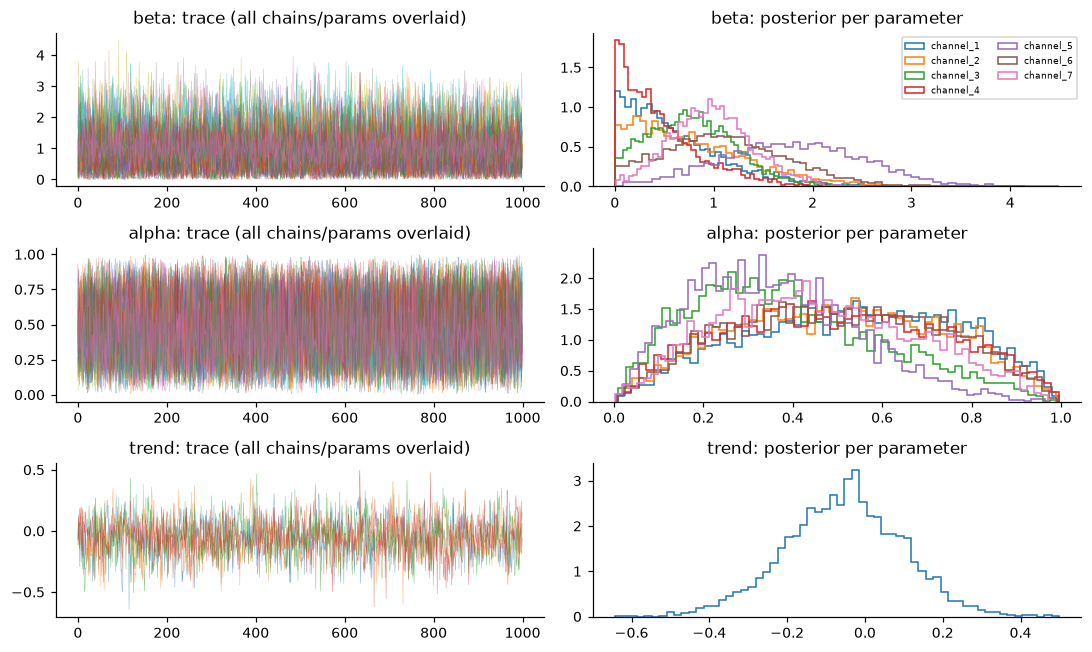

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(10, 6))
for row, var in enumerate(["beta", "alpha", "trend"]):
    draws = idata.posterior[var]
    if var == "trend":
        draws = draws.expand_dims(channel=["trend"], axis=-1)
    for j, ch in enumerate(draws.channel.values):
        series = draws.sel(channel=ch)
        for chain in series.chain.values:
            axes[row, 0].plot(series.sel(chain=chain).values, lw=0.3, alpha=0.6)
        axes[row, 1].hist(series.values.ravel(), bins=60, histtype="step", density=True, label=str(ch))
    axes[row, 0].set_title(f"{var}: trace (all chains/params overlaid)")
    axes[row, 1].set_title(f"{var}: posterior per parameter")
axes[0, 1].legend(fontsize=6, ncol=2)
fig.tight_layout()
savefig(fig, "trace")
plt.show()

All chains mix well (traces look like stationary noise), $\hat R \approx 1.00$, ESS in the thousands, no divergences.
The sampler did its job, so any uncertainty left is genuine uncertainty about the parameters, not a computational
artefact.

### Confounding check: trend vs. channels 5, 6, 7
Section 3.2 predicted that the trend and the channels whose spend shifted in year 2 would compete to explain the
revenue drop. Posterior correlations show whether they do.

,trend,baseline,beta_1,beta_2,beta_3,beta_4,beta_5,beta_6,beta_7
trend,1.00,-0.57,0.04,-0.04,0.02,-0.01,0.57,0.19,-0.57
baseline,-0.57,1.00,-0.05,0.01,-0.31,-0.13,-0.63,-0.17,-0.10
beta_1,0.04,-0.05,1.00,-0.00,-0.03,0.02,-0.04,-0.02,0.01
beta_2,-0.04,0.01,-0.00,1.00,0.02,0.04,-0.02,0.01,-0.01
beta_3,0.02,-0.31,-0.03,0.02,1.00,-0.03,-0.06,-0.01,-0.30
beta_4,-0.01,-0.13,0.02,0.04,-0.03,1.00,0.01,0.01,-0.06
beta_5,0.57,-0.63,-0.04,-0.02,-0.06,0.01,1.00,-0.21,-0.10
beta_6,0.19,-0.17,-0.02,0.01,-0.01,0.01,-0.21,1.00,-0.07
beta_7,-0.57,-0.10,0.01,-0.01,-0.30,-0.06,-0.10,-0.07,1.00


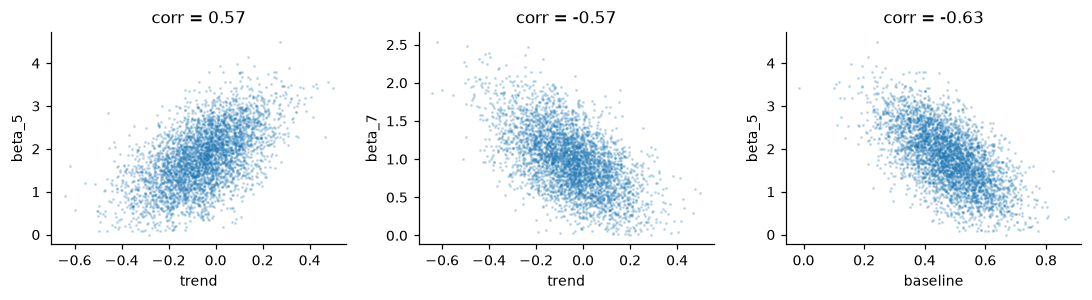

In [15]:
post_check = pd.DataFrame(
    {
        "trend": stacked(idata, "trend"),
        "baseline": stacked(idata, "baseline"),
        **{f"beta_{c.split('_')[1]}": stacked(idata, "beta")[:, i] for i, c in enumerate(CHANNELS)},
    }
)
post_corr = post_check.corr()
display(post_corr.round(2))
post_corr.to_csv(f"{RESULTS_DIR}/posterior_correlations.csv")

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (a, b) in zip(axes, [("trend", "beta_5"), ("trend", "beta_7"), ("baseline", "beta_5")]):
    ax.scatter(post_check[a], post_check[b], s=1, alpha=0.2)
    ax.set(xlabel=a, ylabel=b, title=f"corr = {post_corr.loc[a, b]:.2f}")
fig.tight_layout()
savefig(fig, "posterior_pairs")
plt.show()

The confounding shows up clearly:
- **trend vs. β5: +0.57, trend vs. β7: −0.56.** Revenue fell in year 2, when spend moved from channel 5 to channel 7.
  The model can explain the fall either with a negative trend, or with a high ROI for channel 5 (losing it hurts) and a
  low ROI for channel 7. Draws with a higher β5 need less downward trend, hence the positive correlation.
- **baseline vs. β5: −0.63.** Whatever revenue is not credited to channel 5 has to go to the baseline.

The data pins down *combinations* of these parameters better than each one alone. That is why individual ROI intervals
are wide. The posterior trend is centred near zero (−0.06 ± 0.15), so the model mostly explains the year-2 decline
through the channel mix rather than a general downward trend. A plausible reading, but not one this dataset can
prove.

## 10. Posterior predictive check and fit metrics

The same band plot as section 6, now using the posterior. The bands should be much narrower and track the data.

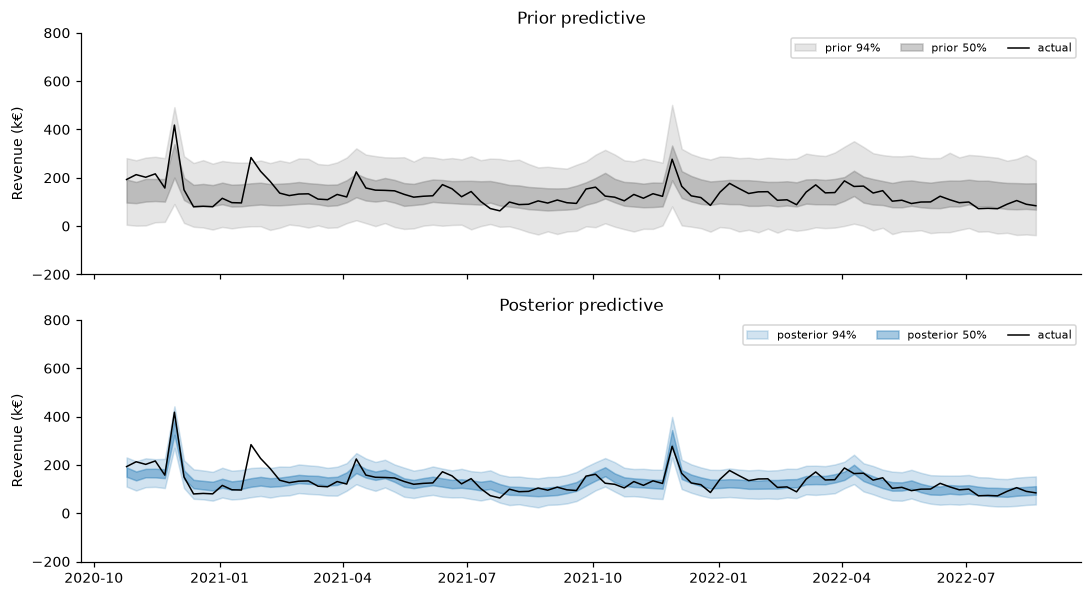

In-sample R² = 0.650 | MAPE = 15.4% (excluding Jan-2021 spike: 14.7%) | 94% interval coverage = 98%


In [16]:
post_rev = stacked(idata, "revenue", "posterior_predictive") * SCALE
mu_mean = stacked(idata, "mu").mean(axis=0) * SCALE
actual = df.revenue.values[FIT_IDX]

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
plot_bands(axes[0], dates[FIT_IDX], prior_rev / 1e3, actual / 1e3, "tab:grey", "prior")
axes[0].set(ylabel="Revenue (k€)", title="Prior predictive", ylim=(-200, 800))
plot_bands(axes[1], dates[FIT_IDX], post_rev / 1e3, actual / 1e3, "tab:blue", "posterior")
axes[1].set(ylabel="Revenue (k€)", title="Posterior predictive", ylim=(-200, 800))
for ax in axes:
    ax.legend(ncol=3, fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "prior_vs_posterior_predictive")
plt.show()

resid = actual - mu_mean
r2 = 1 - (resid**2).sum() / ((actual - actual.mean()) ** 2).sum()
mape = np.mean(np.abs(resid) / actual)
q03, q97 = np.quantile(post_rev, [0.03, 0.97], axis=0)
coverage = np.mean((actual >= q03) & (actual <= q97))
mape_ex = np.mean((np.abs(resid) / actual)[~np.isin(dates[FIT_IDX], JAN_SPIKE.values)])
print(f"In-sample R² = {r2:.3f} | MAPE = {mape:.1%} (excluding Jan-2021 spike: {mape_ex:.1%}) | 94% interval coverage = {coverage:.0%}")

- **$R^2 \approx 0.65$, MAPE ≈ 15%.** A moderate fit. The model is deliberately simple (linear, smooth seasonality) and
  doesn't chase one-off spikes such as January 2021, which alone accounts for a large share of the squared error.
- **94% interval coverage ≈ 97%:** the uncertainty bands are honest, slightly conservative (Student-t tails).
- In-sample fit isn't the real test. LOO (above) and the holdout (below) are.

### Time-based holdout (sanity check)
Refit on weeks 9–92 and forecast the last 12 weeks. **Caveat:** in those weeks channel 1 is zero and channel 6 mostly
zero, so this mainly tests the baseline, trend and seasonality extrapolation, not the channel effects. With 12 points the
metric is noisy. As a reference we use a seasonal naive forecast: revenue in the same week one year earlier.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, baseline, trend, gamma, sigma, cyber_effect, nu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Sampling: [revenue]


Holdout (last 12 weeks): MAPE model = 13.1% | MAPE seasonal naive = 23.3% | 94% coverage = 100%


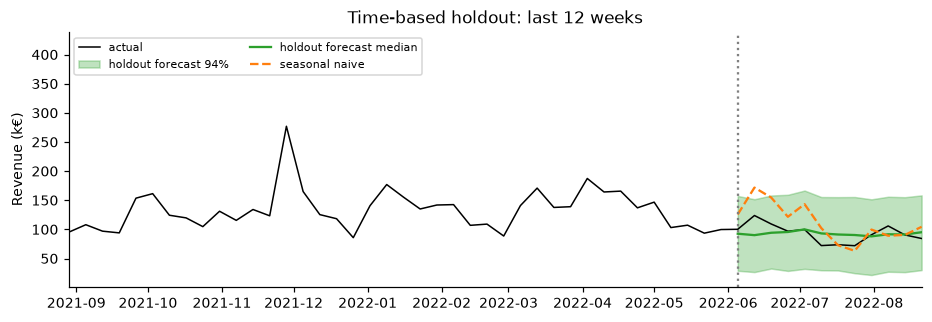

In [17]:
HOLDOUT = 12
train_idx = np.arange(L_MAIN, T - HOLDOUT)
test_idx = np.arange(T - HOLDOUT, T)
idata_train = fit(build_mmm(train_idx))


def predict_mu(d, idx, L=L_MAIN, K=2, cyber=True):
    """Expected (scaled) revenue for weeks `idx` from posterior draws, mirroring build_mmm in NumPy."""
    alpha, beta = stacked(d, "alpha"), stacked(d, "beta")  # (S, C)
    w = alpha[:, :, None] ** np.arange(L + 1)  # (S, C, L+1)
    w = w / w.sum(axis=-1, keepdims=True)
    adstock = np.einsum("ncl,scl->snc", lag_tensor(X, L)[idx], w)
    F, _ = fourier_terms(T, K)
    mu = (stacked(d, "baseline")[:, None] + stacked(d, "trend")[:, None] * t[idx]
          + stacked(d, "gamma") @ F[idx].T + (adstock * beta[:, None, :]).sum(-1))
    if cyber:
        mu += stacked(d, "cyber_effect")[:, None] * CYBER[idx]
    return mu


# Self-check: the NumPy version reproduces the model's own `mu` on the training weeks
assert np.allclose(predict_mu(idata_train, train_idx), stacked(idata_train, "mu"))

mu_test = predict_mu(idata_train, test_idx)
nu_s, sigma_s = stacked(idata_train, "nu"), stacked(idata_train, "sigma")
pred_test = (mu_test + sigma_s[:, None] * RNG.standard_t(nu_s[:, None], size=mu_test.shape)) * SCALE
actual_test = df.revenue.values[test_idx]
naive = df.revenue.values[test_idx - 52]

mape_model = np.mean(np.abs(mu_test.mean(0) * SCALE - actual_test) / actual_test)
mape_naive = np.mean(np.abs(naive - actual_test) / actual_test)
lo, hi = np.quantile(pred_test, [0.03, 0.97], axis=0)
cov_test = np.mean((actual_test >= lo) & (actual_test <= hi))
print(f"Holdout (last {HOLDOUT} weeks): MAPE model = {mape_model:.1%} | MAPE seasonal naive = {mape_naive:.1%} | 94% coverage = {cov_test:.0%}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(dates, df.revenue / 1e3, color="k", lw=1, label="actual")
q = np.quantile(pred_test, [0.03, 0.5, 0.97], axis=0) / 1e3
ax.fill_between(dates[test_idx], q[0], q[2], color="tab:green", alpha=0.3, label="holdout forecast 94%")
ax.plot(dates[test_idx], q[1], color="tab:green", label="holdout forecast median")
ax.plot(dates[test_idx], naive / 1e3, color="tab:orange", ls="--", label="seasonal naive")
ax.axvline(dates[test_idx[0]], color="grey", ls=":")
ax.set(ylabel="Revenue (k€)", title="Time-based holdout: last 12 weeks")
ax.legend(fontsize=7, ncol=2)
ax.set_xlim(dates[52], dates[-1])
savefig(fig, "holdout")
plt.show()

## 11. Prior vs. posterior: what did the data actually teach us?

For each channel, the prior (grey) and posterior (colour) of the ROI $\beta_c$ and the decay $\alpha_c$.
- **Posterior much narrower than the prior / shifted:** the data was informative.
- **Posterior ≈ prior:** the data says little; the result is mostly the prior.

The ratio of posterior to prior standard deviation summarises this per parameter (1 = nothing learned, close to
0 = strongly identified).

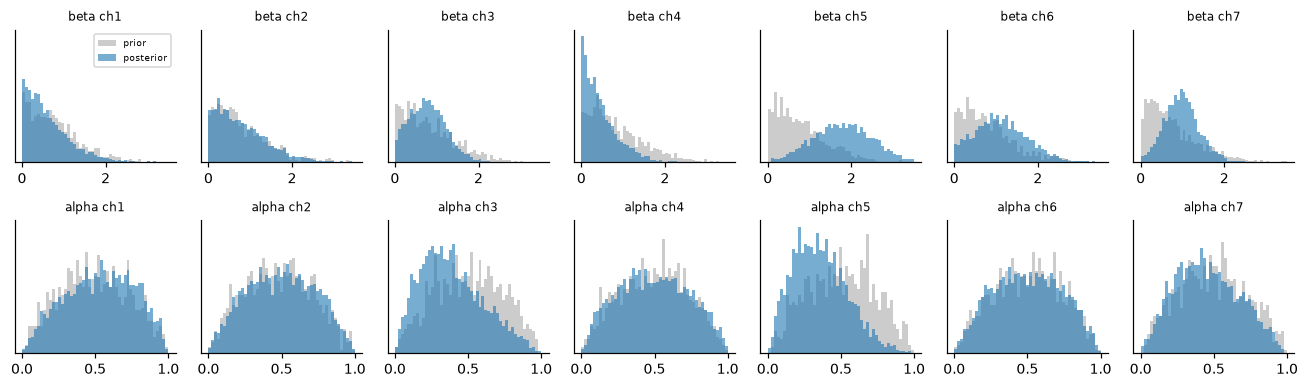

,beta sd ratio,alpha sd ratio,beta prior median,beta posterior median
channel_1,0.86,1.00,0.68,0.49
channel_2,0.97,1.01,0.65,0.68
channel_3,0.70,0.92,0.70,0.76
channel_4,0.64,1.05,0.68,0.36
channel_5,1.18,0.81,0.67,1.79
channel_6,1.02,1.02,0.69,1.08
channel_7,0.68,0.94,0.62,0.97


In [18]:
fig, axes = plt.subplots(2, C, figsize=(12, 3.6), sharey="row")
for row, var in enumerate(["beta", "alpha"]):
    pr, po = stacked(idata, var, "prior"), stacked(idata, var)
    bins = np.linspace(0, 3.5 if var == "beta" else 1, 50)
    for j in range(C):
        ax = axes[row, j]
        ax.hist(pr[:, j], bins=bins, density=True, color="grey", alpha=0.4, label="prior")
        ax.hist(po[:, j], bins=bins, density=True, color="tab:blue", alpha=0.6, label="posterior")
        ax.set_title(f"{var} ch{j + 1}", fontsize=8)
        ax.set_yticks([])
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
savefig(fig, "prior_vs_posterior_params")
plt.show()

shrink = pd.DataFrame(
    {
        f"{var} sd ratio": stacked(idata, var).std(0) / stacked(idata, var, "prior").std(0)
        for var in ["beta", "alpha"]
    }
    | {
        "beta prior median": np.median(stacked(idata, "beta", "prior"), 0),
        "beta posterior median": np.median(stacked(idata, "beta"), 0),
    },
    index=CHANNELS,
)
display(shrink.round(2))
shrink.to_csv(f"{RESULTS_DIR}/prior_posterior_shrinkage.csv")

**Interpretation**
- **Clearly learned:** channel 5 (median ROI moves from the prior's 0.67 to 1.8; its sd ratio is above 1 only because the
  posterior moved into the prior's tail, not because nothing was learned) and channels 3, 4, 7 (posterior ~35% narrower
  than the prior; channel 7 concentrates around 1, channel 4 around low values).
- **Barely learned:** channels 1 and 2 (sd ratio 0.85–0.94, posterior ≈ prior). They have tiny or erratic spend, so their
  ROI is mostly the prior's assumption, not a measurement. Channel 6 shifts upward but stays as wide as its prior.
- **Decay ($\alpha$):** the posteriors stay close to the Beta(2,2) prior for all channels except 3 and 5 (shorter
  carry-over). Weekly data over two years
  carries little information about the *shape* of the carry-over, as long as total ROI is what matters. Normalised
  adstock makes ROI fairly robust to $\alpha$ (section 13 also varies $L$).

## 12. Channel contributions and ROI

### Revenue decomposition
The posterior-mean contribution of each component over time, in €.

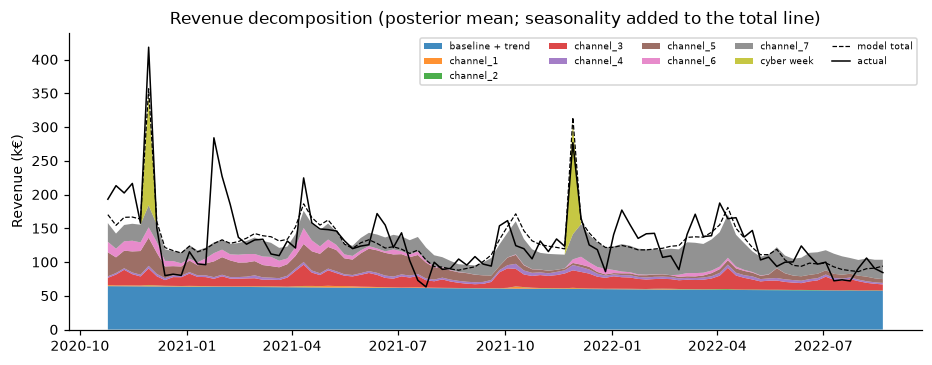

Share of fitted revenue by component:
baseline + trend    46.8%
seasonality         -0.3%
cyber week           2.7%
channel_1            0.6%
channel_2            0.2%
channel_3           11.9%
channel_4            2.5%
channel_5           10.9%
channel_6            3.8%
channel_7           21.0%


In [19]:
F2, _ = fourier_terms(T, 2)
comp = pd.DataFrame(index=dates[FIT_IDX])
comp["baseline + trend"] = (stacked(idata, "baseline")[:, None] + stacked(idata, "trend")[:, None] * t[FIT_IDX]).mean(0)
comp["seasonality"] = stacked(idata, "seasonality").mean(0)
comp["cyber week"] = stacked(idata, "cyber_effect").mean() * CYBER[FIT_IDX]
contrib_draws = stacked(idata, "channel_contrib")  # (S, N, C), scaled
for j, ch in enumerate(CHANNELS):
    comp[ch] = contrib_draws[:, :, j].mean(0)
comp *= SCALE

fig, ax = plt.subplots(figsize=(10, 3.5))
pos_cols = ["baseline + trend"] + CHANNELS + ["cyber week"]
ax.stackplot(comp.index, (comp[pos_cols] / 1e3).T.values, labels=pos_cols, alpha=0.85)
ax.plot(comp.index, (comp.sum(axis=1)) / 1e3, color="k", lw=0.8, ls="--", label="model total")
ax.plot(comp.index, actual / 1e3, color="k", lw=1, label="actual")
ax.set(ylabel="Revenue (k€)", title="Revenue decomposition (posterior mean; seasonality added to the total line)")
ax.legend(ncol=5, fontsize=6, loc="upper right")
savefig(fig, "decomposition")
plt.show()

share = comp.sum() / comp.sum().sum()
print("Share of fitted revenue by component:")
print(share.map("{:.1%}".format).to_string())

### ROI per channel
With common scaling and normalised adstock, $\beta_c$ is the ROI: total revenue generated per € spent, counting all
future weeks. Every posterior draw gives one ROI per channel, so we get a full distribution. We report:
- the median and the 94% HDI,
- $P(\text{ROI} > 1)$: the probability that the channel returns more revenue than it costs,
- $P(\text{best})$: the share of draws in which the channel has the highest ROI.

As a cross-check, the **contribution-based ROI** (attributed revenue in the fitted weeks ÷ spend in the same
weeks) should be close to $\beta_c$. It differs slightly because spend in the last weeks has not finished paying off.

*Note:* this is **revenue** ROI. Without margins we can't tell whether a ROI of 1.2 is profitable.

In [20]:
roi = stacked(idata, "beta")  # (S, C)
spend_fit = df[SPEND_COLS].values[FIT_IDX].sum(0)
roi_contrib = contrib_draws.sum(axis=1) * SCALE / spend_fit
best = np.bincount(roi.argmax(axis=1), minlength=C) / len(roi)
hdi = np.array([az.hdi(roi[:, j], prob=0.94) for j in range(C)])

roi_table = pd.DataFrame(
    {
        "spend (k€, fit weeks)": spend_fit / 1e3,
        "ROI median": np.median(roi, 0),
        "ROI 94% HDI low": hdi[:, 0],
        "ROI 94% HDI high": hdi[:, 1],
        "P(ROI > 1)": (roi > 1).mean(0),
        "P(best)": best,
        "contribution ROI (median)": np.median(roi_contrib, 0),
        "attributed revenue (k€)": np.median(contrib_draws.sum(axis=1) * SCALE, 0) / 1e3,
    },
    index=CHANNELS,
).sort_values("ROI median", ascending=False)
display(roi_table.round(2))
roi_table.to_csv(f"{RESULTS_DIR}/roi_table.csv")

,"spend (k€, fit weeks)",ROI median,ROI 94% HDI low,ROI 94% HDI high,P(ROI > 1),P(best),contribution ROI (median),attributed revenue (k€)
channel_5,738.41,1.79,0.47,3.06,0.87,0.61,1.83,1351.25
channel_6,391.79,1.08,0.01,2.15,0.55,0.18,1.15,452.07
channel_7,2663.34,0.97,0.21,1.76,0.47,0.06,0.97,2592.70
channel_3,1910.41,0.76,0.01,1.47,0.30,0.03,0.76,1449.79
channel_2,33.84,0.68,0.00,1.84,0.33,0.08,0.68,22.90
channel_1,106.48,0.49,0.00,1.59,0.20,0.04,0.51,54.77
channel_4,678.32,0.36,0.00,1.23,0.11,0.01,0.36,243.98


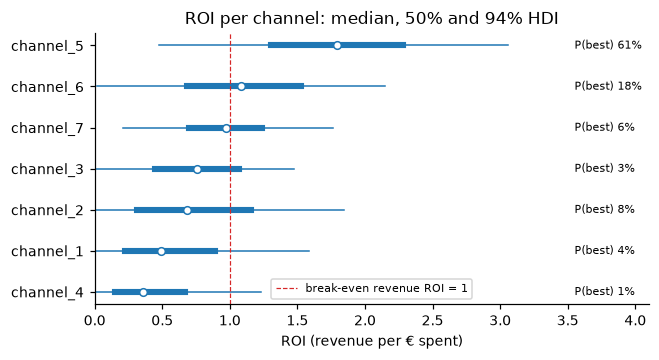

In [21]:
order = roi_table.index[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, ch in enumerate(order):
    j = CHANNELS.index(ch)
    lo, hi = hdi[j]
    q25, q75 = np.quantile(roi[:, j], [0.25, 0.75])
    ax.plot([lo, hi], [i, i], color="tab:blue", lw=1)
    ax.plot([q25, q75], [i, i], color="tab:blue", lw=4)
    ax.plot(np.median(roi[:, j]), i, "o", color="white", mec="tab:blue", ms=5)
    ax.text(3.55, i, f"P(best) {best[j]:.0%}", va="center", fontsize=7)
ax.axvline(1, color="tab:red", ls="--", lw=0.8, label="break-even revenue ROI = 1")
ax.set_yticks(range(C), order)
ax.set(xlabel="ROI (revenue per € spent)", title="ROI per channel: median, 50% and 94% HDI", xlim=(0, 4.1))
ax.legend(fontsize=7, loc="lower center")
savefig(fig, "roi_forest")
plt.show()

## 13. Sensitivity of the ROI ranking

With 96 observations, the priors matter. To check whether the ranking comes from the data or from the priors, we refit
with a tighter and a wider ROI prior, and with a shorter and longer maximum lag $L$. If the ranking holds, it is
driven by the data.

In [22]:
sens_specs = {
    "main: HalfNormal(1), L=8": None,
    "ROI prior HalfNormal(0.5)": dict(beta_sigma=0.5),
    "ROI prior HalfNormal(2)": dict(beta_sigma=2.0),
    "L=4": dict(L=4),
    "L=12": dict(L=12),
}
sens_rows = {}
for name, spec in sens_specs.items():
    if spec is None:
        d = idata
    else:
        L_s = spec.get("L", L_MAIN)
        d = fit(build_mmm(np.arange(max(L_s, L_MAIN), T), **spec))  # same fitted weeks except for L=12
    r = stacked(d, "beta")
    row = pd.Series(np.median(r, 0), index=CHANNELS)
    row["top channel"] = CHANNELS[int(np.argmax(np.bincount(r.argmax(1), minlength=C)))]
    row["P(top)"] = np.bincount(r.argmax(1), minlength=C).max() / len(r)
    row["divergences"] = int(d.sample_stats.diverging.sum())
    sens_rows[name] = row
sensitivity = pd.DataFrame(sens_rows).T
sensitivity[CHANNELS + ["P(top)"]] = sensitivity[CHANNELS + ["P(top)"]].astype(float).round(2)
display(sensitivity)
sensitivity.to_csv(f"{RESULTS_DIR}/sensitivity.csv")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, baseline, trend, gamma, sigma, cyber_effect, nu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Sampling: [revenue]


...

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, baseline, trend, gamma, sigma, cyber_effect, nu]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Sampling: [revenue]


,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6,channel_7,top channel,P(top),divergences
"main: HalfNormal(1), L=8",0.49,0.68,0.76,0.36,1.79,1.08,0.97,channel_5,0.61,0
ROI prior HalfNormal(0.5),0.30,0.35,0.57,0.26,0.82,0.60,0.83,channel_5,0.34,0
ROI prior HalfNormal(2),0.74,1.36,0.79,0.44,2.70,1.25,1.01,channel_5,0.64,0
L=4,0.48,0.67,0.72,0.34,1.84,0.97,0.90,channel_5,0.66,0
L=12,0.54,0.65,0.87,0.52,1.60,0.67,0.79,channel_5,0.57,0


**Reading the sensitivity table**
- **The ranking is robust.** Channel 5 is the top channel under every prior and every lag, and channel 4 is always at or near
  the bottom.
- **The magnitude is not.** Channel 5's median ROI ranges from ~0.8 (tight prior) to ~2.8 (wide prior). With 96 weeks
  the data can't fully overrule the prior on the size of the effect. Reported ROI values should be read as "under a
  weakly informative prior centred on break-even".
- Under the tight HalfNormal(0.5) prior, every channel is pulled towards 0 and P(top) for channel 5 drops to ~0.3:
  that prior is too strong for the data to separate the channels.
- Longer lags (L=12) lower channel 6's ROI, so channel 6's second place is fragile.

## 14. Summary

The printed numbers above are the source of truth. The key findings (see the PDF report for the full write-up):

1. **Carry-over** is modelled with normalised geometric adstock (one decay rate per channel, $L=8$). Normalisation
   keeps $\beta_c$ interpretable as ROI. The data says little about the decay rates themselves.
2. **Priors** are set on the ROI scale thanks to common scaling: HalfNormal(1) on ROI is wide but excludes absurd values.
   The prior predictive check confirms the priors generate plausible revenue.
3. **Prior vs. posterior:** the posterior predictive is far narrower than the prior predictive and tracks the data. ROI
   is clearly learned for channels 5, 3, 4 and 7; channels 1 and 2 stay close to the prior; decay rates are mostly prior.
4. **Performance:** clean diagnostics (R-hat < 1.01, ESS > 1,000, 0 divergences); in-sample R² ≈ 0.65, MAPE ≈ 15%,
   calibrated intervals; LOO differences between variants are within ~1 SE, so model choices rest on Pareto-k, ν and domain reasoning; holdout MAPE ≈ 13% vs. 23% for a seasonal
   naive forecast (with caveats).
5. **Channel insights:** ads explain ~half of revenue. Channel 7 brings the most revenue in absolute terms (largest
   budget, ROI ≈ 1); channel 5 is the most efficient. Channel 4 and, less certainly, channels 1 and 3 return well below 1 €
   per €. Year 2's shift from 5/6 to 7 coincided with lower revenue, which fits this ranking, but trend and these
   channels are confounded.
6. **ROI:** channel 5 is best with median ROI ≈ 1.8 (94% HDI 0.4–3.1), P(ROI > 1) ≈ 0.87, P(best) ≈ 0.61. The ranking
   holds across priors and lags; the size of the ROI depends on the prior.